# Slot 1: Moving-average crossover, tuning and selection

**Protocol** (fixed *before* looking at results; see `docs/IMPLEMENTATION_PLAN.md` §3–4):

| Stage | What | Data |
|---|---|---|
| 1 | Grid over `short × long × ma_type`. Pick the **centre of the most stable region** per MA type (3×3 neighbourhood-averaged Sharpe), not the single best cell | train |
| 2 | For those two base pairs, grid `band × reentry_window`. Keep the top 2 per base by Sharpe (requiring ≥ 10 trades) → **4 candidates** | train |
| 3 | Evaluate *only* the 4 candidates and the v1 default. Keep candidates whose max drawdown is no worse than buy-and-hold's; choose the highest Sharpe. **Tie-break** (plan §4): candidates within 0.1 Sharpe of the best → higher Calmar → simpler model (fewer active features) | validation |
| 4 | **Volatility cap** on the stage-3 choice: `vol_target ∈ {none, "train" (QQQ's train volatility), 25%, 30%} × vol_band ∈ {10%, 20%}`. Pick the best capped variant by Sharpe; **adopt it only if** it is at least as good as the uncapped version on train (Sharpe ≥, max DD no worse) **and** confirms on validation (Sharpe ≥ uncapped − 0.05, max DD no worse) | train → validation |
| 5 | Diagnostics: bootstrap Sharpe CIs, cost sensitivity, crash close-ups | train + validation |

The test period is **not** touched here.

**Engine conventions:** 5 bps one-way costs. Uninvested cash earns the 13-week T-bill rate, and **Sharpe/Sortino are in excess of T-bills** (see `data/README.md`).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from pathlib import Path
from qqq import config
from qqq.data import load_prices
from qqq.backtest import run_backtest, trade_stats
from qqq.metrics import compute_metrics, bootstrap_sharpe_ci, drawdown_series
from qqq.evaluate import grid_search, backtest_strategy, PERIODS, period_metrics
from qqq.strategies.base import BuyAndHold
from qqq.strategies.moving_average import MovingAverageCrossover as MA
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
prices = load_prices("csv")
COLS = ["annualized_return", "annualized_volatility", "sharpe_ratio", "max_drawdown", "cumulative_return", "exposure", "n_position_changes"]
def pct(df):
    f = {c: "{:.1%}" for c in ["annualized_return","annualized_volatility","max_drawdown","cumulative_return","exposure"]}
    f |= {"sharpe_ratio": "{:.2f}", "n_position_changes": "{:.0f}"}
    return df.style.format({k: v for k, v in f.items() if k in df.columns})
bh = period_metrics(backtest_strategy(BuyAndHold(), prices))
print(f"{len(prices)} trading days, {prices.index[0].date()} -> {prices.index[-1].date()}")

5492 trading days, 2005-01-03 -> 2026-10-30


## 0. Baseline: v1 default (50/200 SMA) vs buy-and-hold

In [2]:
NOCAP = dict(vol_target=None)  # stages 0-3 tune the signal without the cap (stage 4 adds it)
base = period_metrics(backtest_strategy(MA(50, 200, reentry_window=None, **NOCAP), prices))
pct(pd.concat({"MA 50/200 (v1)": base, "buy_and_hold": bh})[COLS])

## 1. Window grid on train

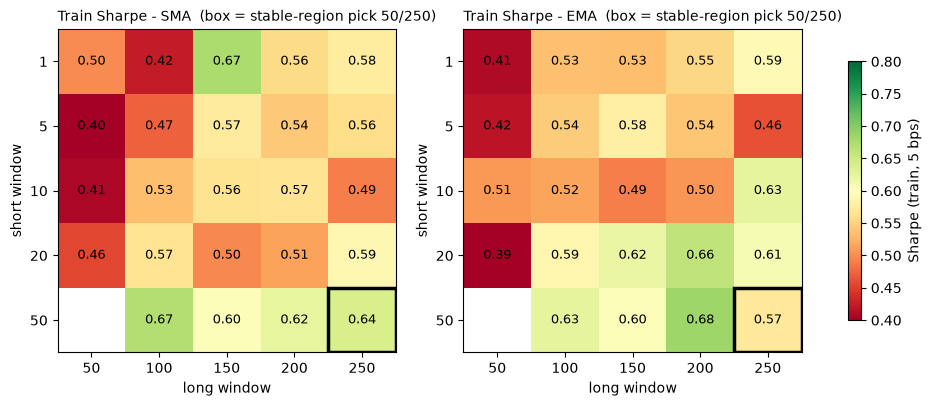

Stage-1 base pairs: {'sma': (50, 250), 'ema': (50, 250)}


In [3]:
SHORTS, LONGS = [1, 5, 10, 20, 50], [50, 100, 150, 200, 250]
g1 = grid_search(MA, {"short_window": SHORTS, "long_window": LONGS, "ma_type": ["sma", "ema"]}, period="train", prices=prices,
                 reentry_window=None, **NOCAP)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
bases = {}
for ax, t in zip(axes, ["sma", "ema"]):
    pv = g1[g1.ma_type == t].pivot(index="short_window", columns="long_window", values="sharpe_ratio").reindex(index=SHORTS, columns=LONGS)
    im = ax.imshow(pv.values, cmap="RdYlGn", vmin=0.4, vmax=0.8, aspect="auto")
    ax.set_xticks(range(len(LONGS)), LONGS); ax.set_yticks(range(len(SHORTS)), SHORTS)
    ax.set_xlabel("long window"); ax.set_ylabel("short window")
    for i in range(len(SHORTS)):
        for j in range(len(LONGS)):
            if not np.isnan(pv.values[i, j]):
                ax.text(j, i, f"{pv.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
    # stability: 3x3 neighbourhood mean (ignoring invalid cells)
    sm = pv.rolling(3, center=True, min_periods=1).mean().T.rolling(3, center=True, min_periods=1).mean().T
    sm = sm.where(pv.notna())
    i, j = np.unravel_index(np.nanargmax(sm.values), sm.shape)
    bases[t] = (SHORTS[i], LONGS[j])
    ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, lw=2.5, ec="black"))
    ax.set_title(f"Train Sharpe - {t.upper()}  (box = stable-region pick {SHORTS[i]}/{LONGS[j]})", loc="left", fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.8, label="Sharpe (train, 5 bps)")
fig.savefig(FIG / "heatmap_train_sharpe.png", dpi=150, bbox_inches="tight"); plt.show()
print("Stage-1 base pairs:", bases)

**Reading the heat maps:** train Sharpe ranges from about 0.45 to 0.75. Slower long windows (≥ 100) generally beat 50. Neighbouring cells differ by up to 0.1, which is within estimation noise for 14 years of daily data. That's why we pick the centre of a stable region instead of the brightest cell.

## 2. Band × fast re-entry on train, for each base pair

In [4]:
rows = []
for t, (s, l) in bases.items():
    g = grid_search(MA, {"band": [0.0, 0.01, 0.02], "reentry_window": [None, 20, 50, 100]}, period="train", prices=prices,
                    short_window=s, long_window=l, ma_type=t, **NOCAP)
    g["short_window"], g["long_window"], g["ma_type"] = s, l, t
    for _, r in g.iterrows():
        kw = dict(short_window=s, long_window=l, ma_type=t, band=r.band,
                  reentry_window=None if pd.isna(r.reentry_window) else int(r.reentry_window), **NOCAP)
        res = backtest_strategy(MA(**kw), prices).slice(*PERIODS["train"])
        rows.append(kw | {"sharpe_ratio": r.sharpe_ratio, "annualized_return": r.annualized_return,
                          "max_drawdown": r.max_drawdown, "n_position_changes": trade_stats(res)["n_position_changes"]})
g2 = pd.DataFrame(rows)
g2["reentry_window"] = g2["reentry_window"].astype("Int64")
g2.sort_values("sharpe_ratio", ascending=False).round(3)

,short_window,long_window,ma_type,band,reentry_window,vol_target,sharpe_ratio,annualized_return,max_drawdown,n_position_changes
12,50,250,ema,0.02,50,None,0.733,0.128,-0.327,27
0,50,250,sma,0.00,50,None,0.728,0.126,-0.306,38
1,50,250,sma,0.01,50,None,0.724,0.124,-0.276,42
13,50,250,ema,0.02,100,None,0.721,0.124,-0.309,23
14,50,250,ema,0.01,50,None,0.697,0.121,-0.348,28
15,50,250,ema,0.01,100,None,0.694,0.119,-0.311,26
2,50,250,sma,0.00,100,None,0.683,0.115,-0.333,36
16,50,250,ema,0.02,20,None,0.673,0.118,-0.345,51
3,50,250,sma,0.02,50,None,0.672,0.116,-0.277,42
17,50,250,ema,0.02,<NA>,None,0.671,0.110,-0.228,5


In [5]:
cands = (g2[g2.n_position_changes >= 10]
         .sort_values("sharpe_ratio", ascending=False)
         .groupby("ma_type", sort=False).head(2))
def label(r):
    re = "" if pd.isna(r.reentry_window) else f" re{int(r.reentry_window)}"
    return f"{r.ma_type.upper()} {r.short_window}/{r.long_window} band{r.band:.0%}{re}"
CANDIDATES = {label(r): dict(short_window=int(r.short_window), long_window=int(r.long_window), ma_type=r.ma_type, band=float(r.band),
                             reentry_window=None if pd.isna(r.reentry_window) else int(r.reentry_window), **NOCAP)
              for _, r in cands.iterrows()}
CANDIDATES

{'EMA 50/250 band2% re50': {'short_window': 50,
  'long_window': 250,
  'ma_type': 'ema',
  'band': 0.02,
  'reentry_window': 50,
  'vol_target': None},
 'SMA 50/250 band0% re50': {'short_window': 50,
  'long_window': 250,
  'ma_type': 'sma',
  'band': 0.0,
  'reentry_window': 50,
  'vol_target': None},
 'SMA 50/250 band1% re50': {'short_window': 50,
  'long_window': 250,
  'ma_type': 'sma',
  'band': 0.01,
  'reentry_window': 50,
  'vol_target': None},
 'EMA 50/250 band2% re100': {'short_window': 50,
  'long_window': 250,
  'ma_type': 'ema',
  'band': 0.02,
  'reentry_window': 100,
  'vol_target': None}}

## 3. Validation: the 4 candidates and the v1 default, evaluated once

In [6]:
configs = {"v1 default SMA 50/200": dict(short_window=50, long_window=200, reentry_window=None, **NOCAP)} | CANDIDATES
results = {k: backtest_strategy(MA(**kw), prices) for k, kw in configs.items()}
results["buy_and_hold"] = backtest_strategy(BuyAndHold(), prices)
tbl = pd.concat({k: period_metrics(r) for k, r in results.items()})[COLS + ["calmar_ratio"]]
tbl["sharpe_10bps"] = [run_backtest(prices, results[k].positions, 10).slice(*PERIODS[p]).metrics()["sharpe_ratio"]
                       for k, p in tbl.index]
pct(tbl)

In [7]:
val = tbl.xs("validation", level=1)
bh_mdd = val.loc["buy_and_hold", "max_drawdown"]
eligible = val.drop(index="buy_and_hold")
eligible = eligible[eligible.index.isin(list(CANDIDATES))]
ok = eligible[eligible.max_drawdown >= bh_mdd - 1e-9]
pick_from = (ok if len(ok) else eligible).copy()
complexity = {k: (kw["ma_type"] != "sma") + (kw["band"] > 0) + (kw["reentry_window"] is not None) for k, kw in CANDIDATES.items()}
pick_from["complexity"] = pick_from.index.map(complexity)
near_best = pick_from[pick_from.sharpe_ratio >= pick_from.sharpe_ratio.max() - 0.1]
ranked = near_best.assign(calmar=near_best.calmar_ratio.round(3)).sort_values(["calmar", "complexity"], ascending=[False, True])
CHOSEN = ranked.index[0]
FINAL = CANDIDATES[CHOSEN]
print("Eligible (drawdown no worse than B&H):", list(ok.index))
display(ranked[["sharpe_ratio", "calmar", "complexity", "exposure", "n_position_changes"]])
print("CHOSEN:", CHOSEN, FINAL)

Eligible (drawdown no worse than B&H): ['EMA 50/250 band2% re50', 'SMA 50/250 band0% re50', 'SMA 50/250 band1% re50', 'EMA 50/250 band2% re100']


,sharpe_ratio,calmar,complexity,exposure,n_position_changes
SMA 50/250 band0% re50,1.327087,1.247,1,0.988111,1.0
SMA 50/250 band1% re50,1.327087,1.247,2,0.988111,1.0
EMA 50/250 band2% re100,1.313511,1.236,3,0.977543,2.0
EMA 50/250 band2% re50,1.301442,1.225,3,0.989432,4.0


CHOSEN: SMA 50/250 band0% re50 {'short_window': 50, 'long_window': 250, 'ma_type': 'sma', 'band': 0.0, 'reentry_window': 50, 'vol_target': None}


**Caveat: validation has little power to tell these candidates apart.** In 2019–2021 every candidate is long about 98% of the time and trades only 1–4 times. The COVID crash was too short to turn a slow 250-day trend signal negative. So all candidates have the same max drawdown as buy-and-hold and Sharpe ratios within about 0.03 of each other. Validation does confirm the main point: **fast re-entry fixes v1's COVID problem**, since v1 sat out the rebound (exposure 90%, Sharpe 1.13). The ranking among candidates rests mostly on the 14-year train period, which has real bear markets. The test period (2022 bear market and 2023–26 rally) will be the first period where the strategy has to time a sustained decline out of sample.

## 4. Volatility cap (Moreira & Muir 2017)

Hold `signal × min(1, target ÷ 20-day realized volatility)`. This cuts exposure in turbulent markets, where crashes cluster, and never adds leverage. A rebalance band avoids daily trading. The grid is ranked on **train**, and the adoption rule (see the protocol table) was fixed before running this cell.

In [8]:
BASE = dict(FINAL)
grid_v = grid_search(MA, {"vol_target": ["train", 0.25, 0.30], "vol_band": [0.1, 0.2]}, period="train",
                     prices=prices, **{k: v for k, v in BASE.items() if k != "vol_target"})
uncapped_tr = period_metrics(backtest_strategy(MA(**BASE), prices)).loc["train"]
grid_v["vol_target"] = grid_v["vol_target"].astype(str)
display(grid_v[["vol_target", "vol_band", "sharpe_ratio", "annualized_return", "max_drawdown"]].round(3))
print(f"uncapped train: Sharpe {uncapped_tr.sharpe_ratio:.3f}, max DD {uncapped_tr.max_drawdown:.3f}")

,vol_target,vol_band,sharpe_ratio,annualized_return,max_drawdown
0,train,0.1,0.765,0.121,-0.268
1,train,0.2,0.759,0.121,-0.280
2,0.25,0.1,0.735,0.122,-0.292
3,0.25,0.2,0.731,0.121,-0.300
4,0.3,0.1,0.728,0.124,-0.298
5,0.3,0.2,0.720,0.123,-0.298


uncapped train: Sharpe 0.728, max DD -0.306


In [9]:
best = grid_v.iloc[0]
vt = best.vol_target if best.vol_target == "train" else float(best.vol_target)
CAPPED = BASE | {"vol_target": vt, "vol_band": float(best.vol_band)}
cap_m = period_metrics(backtest_strategy(MA(**CAPPED), prices))
unc_m = period_metrics(backtest_strategy(MA(**BASE), prices))
train_ok = (cap_m.loc["train", "sharpe_ratio"] >= unc_m.loc["train", "sharpe_ratio"]
            and cap_m.loc["train", "max_drawdown"] >= unc_m.loc["train", "max_drawdown"])
val_ok = (cap_m.loc["validation", "sharpe_ratio"] >= unc_m.loc["validation", "sharpe_ratio"] - 0.05
          and cap_m.loc["validation", "max_drawdown"] >= unc_m.loc["validation", "max_drawdown"])
ADOPT_CAP = bool(train_ok and val_ok)
fitted = MA(**CAPPED).fit(prices.loc[:config.TRAIN_END]).fitted_vol_target_
print("best capped variant on train:", CAPPED, f"(fitted target = {fitted:.1%})" if fitted else "")
print(f"train check: {train_ok}   validation check: {val_ok}   ->  ADOPT CAP: {ADOPT_CAP}")
if ADOPT_CAP:
    FINAL = CAPPED
    CHOSEN = CHOSEN + " + vol cap"
    results[CHOSEN] = backtest_strategy(MA(**FINAL), prices)
    tbl = pd.concat([tbl, pd.concat({CHOSEN: cap_m})[COLS + ["calmar_ratio"]]])
pct(pd.concat({"uncapped": unc_m, "capped": cap_m})[COLS])

best capped variant on train: {'short_window': 50, 'long_window': 250, 'ma_type': 'sma', 'band': 0.0, 'reentry_window': 50, 'vol_target': 'train', 'vol_band': 0.1} (fitted target = 20.2%)
train check: True   validation check: True   ->  ADOPT CAP: True


## 5. Diagnostics for the chosen configuration

In [10]:
chosen, v1, bhr = results[CHOSEN], results["v1 default SMA 50/200"], results["buy_and_hold"]
ci = {}
for name, r in {"chosen": chosen, "v1": v1, "buy_and_hold": bhr}.items():
    for p in ("train", "validation"):
        sub = r.slice(*PERIODS[p])
        lo, hi = bootstrap_sharpe_ci(sub.returns, rf_daily=sub.rf)
        ci[(name, p)] = {"sharpe": sub.metrics()["sharpe_ratio"], "ci_low": lo, "ci_high": hi}
pd.DataFrame(ci).T.round(2)

sharpe  ci_low  ci_high
chosen       train         0.76    0.31     1.28
             validation    1.44    0.33     2.62
v1           train         0.62    0.17     1.12
             validation    1.10    0.09     2.40
buy_and_hold train         0.56    0.12     1.09
             validation    1.38    0.29     2.68

**Interpretation:** the 95% block-bootstrap intervals are wide, around ±0.5 Sharpe, and overlap heavily between all three. On Sharpe alone, **none of the differences are statistically significant**. That's normal for daily equity strategies over 3–14 years, and it belongs in the report. The more robust difference is in **drawdown**.

In [11]:
costs = [0, 5, 10, 20]
pd.DataFrame({c: {p: run_backtest(prices, chosen.positions, c).slice(*PERIODS[p]).metrics()["sharpe_ratio"]
                  for p in ("train", "validation")} for c in costs}).rename(columns=lambda c: f"{c} bps").round(2)

,0 bps,5 bps,10 bps,20 bps
train,0.77,0.76,0.76,0.74
validation,1.44,1.44,1.43,1.42


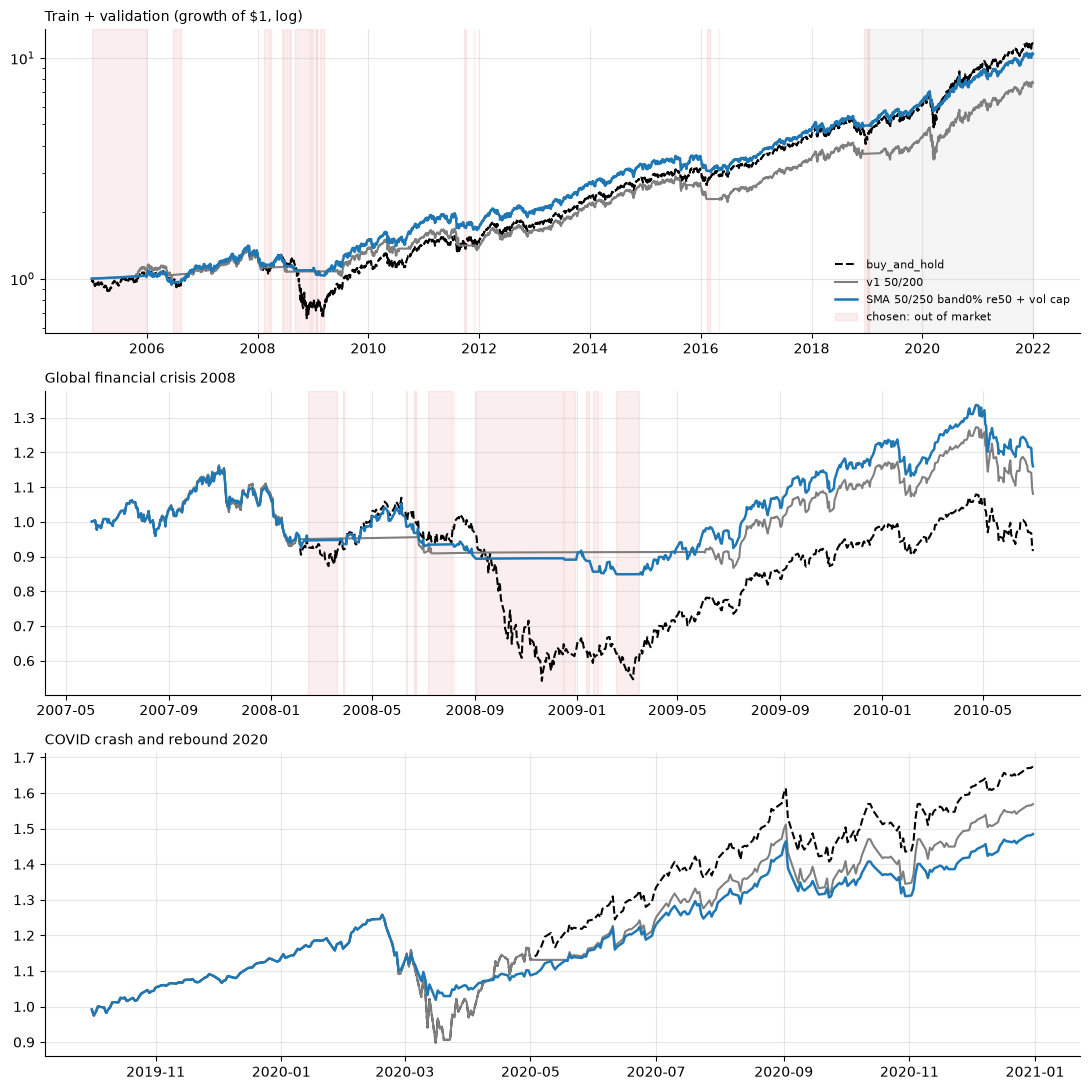

In [12]:
def panel(ax, start, end, title):
    for name, r, kw in [("buy_and_hold", bhr, dict(color="black", ls="--")), ("v1 50/200", v1, dict(color="tab:grey")), (CHOSEN, chosen, dict(color="tab:blue", lw=1.8))]:
        s = r.slice(start, end)
        ax.plot(s.equity, label=name, **kw)
    inn = chosen.positions.loc[start:end] > 0
    ax.fill_between(inn.index, 0, 1, where=~inn, transform=ax.get_xaxis_transform(), color="tab:red", alpha=0.08, label="chosen: out of market")
    ax.set_title(title, loc="left", fontsize=10); ax.grid(alpha=.3); ax.spines[["top", "right"]].set_visible(False)

fig, axes = plt.subplots(3, 1, figsize=(11, 11))
panel(axes[0], None, config.VALIDATION_END, "Train + validation (growth of $1, log)"); axes[0].set_yscale("log")
axes[0].axvspan(pd.Timestamp(config.VALIDATION_START), pd.Timestamp(config.VALIDATION_END), color="grey", alpha=.08)
panel(axes[1], "2007-06-01", "2010-06-30", "Global financial crisis 2008")
panel(axes[2], "2019-10-01", "2020-12-31", "COVID crash and rebound 2020")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "equity_and_crashes.png", dpi=150); plt.show()

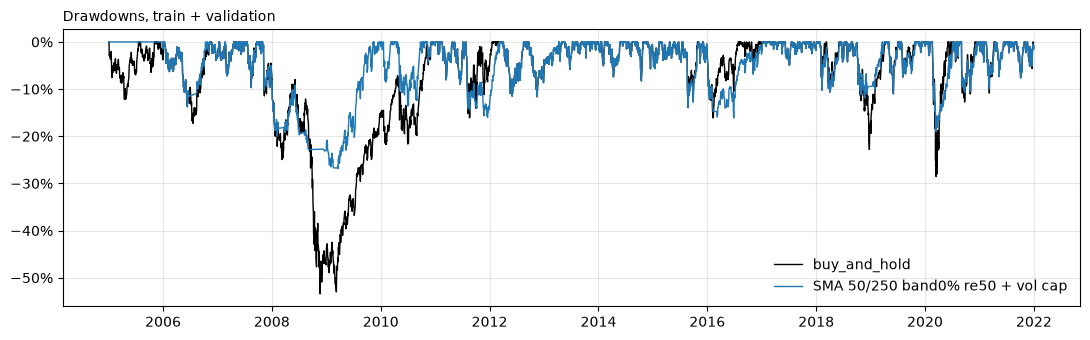

In [13]:
fig, ax = plt.subplots(figsize=(11, 3.5))
for name, r, c in [("buy_and_hold", bhr, "black"), (CHOSEN, chosen, "tab:blue")]:
    ax.plot(drawdown_series(r.slice(None, config.VALIDATION_END).returns), label=name, color=c, lw=1)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0)); ax.legend(frameon=False); ax.grid(alpha=.3)
ax.set_title("Drawdowns, train + validation", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "drawdowns.png", dpi=150); plt.show()

## 6. Result

The chosen configuration (printed below) becomes the default in `MovingAverageCrossover.__init__`. With `vol_target="train"` the cap is QQQ's realized volatility on the training period, computed inside `fit()`. `tests/test_moving_average.py::test_defaults_match_tuning` keeps the code and this notebook in sync.

In [14]:
print("FINAL defaults:", FINAL)
pct(tbl.loc[[CHOSEN, "v1 default SMA 50/200", "buy_and_hold"]])

FINAL defaults: {'short_window': 50, 'long_window': 250, 'ma_type': 'sma', 'band': 0.0, 'reentry_window': 50, 'vol_target': 'train', 'vol_band': 0.1}
